# Diabetes screening model

This notebook trains the model used in Glucorisk. It uses 12 health factors from the 2023 CDC BRFSS survey. The target combines self-reported diabetes and prediabetes.

Data: https://www.cdc.gov/brfss/annual_data/annual_2023.html


## Setup

Install SHAP for feature analysis, skl2onnx for export, and ONNX Runtime to check the exported model.


In [ ]:
!pip install shap skl2onnx onnxruntime --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.2/317.2 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 88.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 71.4 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.pipeline import Pipeline
from sklearn.calibration import _sigmoid_calibration, calibration_curve
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, AdaBoostClassifier,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV

import shap

## Load the data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
xpt_path = "/content/drive/MyDrive/diabetes_prediction_app/LLCP2023.XPT"

if not os.path.exists(xpt_path):
    raise FileNotFoundError(f"Couldn't find {xpt_path}")

print("Found file:", xpt_path)

Found file: /content/drive/MyDrive/diabetes_prediction_app/LLCP2023.XPT


In [ ]:
# Load the CDC SAS transport file.
df_raw = pd.read_sas(xpt_path, format="xport", encoding="latin-1")
print(f"Loaded {len(df_raw):,} rows, {len(df_raw.columns)} columns")

Loaded 433,323 rows, 350 columns


## Clean the data and select features

DIABETE4 records whether a respondent was told they had diabetes. Diabetes and prediabetes responses form the positive class; no diabetes forms the negative class. Gestational-only diabetes is excluded.

The features use health information available without a blood test. Print the column names below to check the survey variables.


In [ ]:
pd.set_option('display.max_rows', None)
for col in sorted(df_raw.columns.tolist()):
    print(col)

ACEADNED
ACEADSAF
ACEDEPRS
ACEDIVRC
ACEDRINK
ACEDRUGS
ACEHURT1
ACEHVSEX
ACEPRISN
ACEPUNCH
ACESWEAR
ACETOUCH
ACETTHEM
ACTIN13_
ACTIN23_
ADDEPEV3
ALCDAY4
ARTHDIS2
ARTHEDU
ARTHEXER
ASPIRIN
ASTHMA3
ASTHNOW
AVEDRNK3
BIRTHSEX
BLDSTFIT
BLIND
BPHIGH6
BPMEDS1
CADULT1
CAGEG
CAREGIV1
CASTHDX2
CASTHNO2
CCLGHOUS
CDDISCU1
CDHOUS1
CDSOCIA1
CDWORRY
CELLFON5
CELLSEX2
CELPHON1
CELSXBRT
CERVSCRN
CHCCOPD3
CHCKDNY2
CHCOCNC1
CHCSCNC1
CHECKUP1
CHILDREN
CHKHEMO3
CHOLCHK3
CHOLMED3
CIMEMLO1
CNCRAGE
CNCRDIFF
CNCRTYP2
COLGHOUS
COLNCNCR
COLNSIGM
COLNTES1
COVACGE1
COVIDACT
COVIDNU2
COVIDPO1
COVIDSM1
COVIDVA1
CPDEMO1C
CRGVALZD
CRGVEXPT
CRGVHOU1
CRGVHRS1
CRGVLNG1
CRGVPER1
CRGVPRB3
CRGVREL4
CRVCLCNC
CRVCLHPV
CRVCLPAP
CSRVCLIN
CSRVCTL2
CSRVDEIN
CSRVDOC1
CSRVINSR
CSRVINST
CSRVPAIN
CSRVRTRN
CSRVSUM
CSRVTRT3
CSTATE1
CTELENM1
CTELNUM1
CVDCRHD4
CVDINFR4
CVDSTRK3
DEAF
DECIDE
DIABAGE4
DIABEDU1
DIABETE4
DIABEYE1
DIABTYPE
DIFFALON
DIFFDRES
DIFFWALK
DISPCODE
DRNK3GE5
DRNKANY6
DRNKDRI2
DROCDY4_
ECIGNOW2
EDUCA
EMPLOY1
EMTSUPRT
EXE

In [ ]:
# Encode the survey target and health-history variables.
df = df_raw[df_raw["DIABETE4"].isin([1, 3, 4])].copy()
df["at_risk"] = df["DIABETE4"].map({1: 1, 4: 1, 3: 0})

# Combine high and borderline high blood pressure.
df = df[df["BPHIGH6"].isin([1, 3, 4])].copy()
df["high_bp"] = df["BPHIGH6"].map({1: 1, 4: 1, 3: 0})

df = df[df["TOLDHI3"].isin([1, 2])].copy()
df["high_chol"] = df["TOLDHI3"].map({1: 1, 2: 0})

df = df[df["DIFFWALK"].isin([1, 2])].copy()
df["diff_walk"] = df["DIFFWALK"].map({1: 1, 2: 0})

# Keep stroke, coronary heart disease, and heart attack as separate inputs.
df = df[df["CVDSTRK3"].isin([1, 2])].copy()
df["stroke_history"] = df["CVDSTRK3"].map({1: 1, 2: 0})

df = df[df["CVDCRHD4"].isin([1, 2])].copy()
df["angina_chd_history"] = df["CVDCRHD4"].map({1: 1, 2: 0})

df = df[df["CVDINFR4"].isin([1, 2])].copy()
df["heart_attack_history"] = df["CVDINFR4"].map({1: 1, 2: 0})

FEATURES = [
    "GENHLTH", "_AGEG5YR", "SEXVAR", "_BMI5", "EXERANY2",
    "high_bp", "high_chol", "SMOKE100", "diff_walk",
    "stroke_history", "angina_chd_history", "heart_attack_history",
]

missing_cols = [c for c in ["GENHLTH", "_AGEG5YR", "SEXVAR", "_BMI5", "EXERANY2", "SMOKE100"] if c not in df.columns]
if missing_cols:
    print("WARNING - columns not found, check this year's codebook:", missing_cols)
else:
    print("All expected columns found.")

model_df = df[FEATURES + ["at_risk"]].copy()

for col in ["GENHLTH", "EXERANY2", "SMOKE100"]:
    model_df = model_df[~model_df[col].isin([7, 9])]
model_df = model_df[model_df["_BMI5"].notna()]

# Remove rows with any remaining missing features.
model_df = model_df.dropna(subset=FEATURES)

print(f"{len(model_df):,} rows remain after cleaning")
print(model_df["at_risk"].value_counts(normalize=True))

All expected columns found.
324,787 rows remain after cleaning
at_risk
0    0.824273
1    0.175727
Name: proportion, dtype: float64


## Split the data

Use 80% for training, 10% for validation, and 10% for testing. Stratify by the target so each split has a similar proportion of positive cases.


In [ ]:
train_df, temp_df = train_test_split(
    model_df, test_size=0.20, random_state=42, stratify=model_df["at_risk"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["at_risk"]
)

print(f"Train: {len(train_df):,} rows")
print(f"Validation: {len(val_df):,} rows")
print(f"Test: {len(test_df):,} rows")

Train: 259,829 rows
Validation: 32,479 rows
Test: 32,479 rows


## Class weights

About 18% of the cleaned responses are positive. Give the two classes equal total weight when the classifier supports sample weights.


In [ ]:
X_train, y_train = train_df[FEATURES], train_df["at_risk"]
X_val, y_val = val_df[FEATURES], val_df["at_risk"]
X_test, y_test = test_df[FEATURES], test_df["at_risk"]

sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## Compare models

Train each classifier and compare validation AUC. Select the model with the highest score before evaluating it on the test set.


In [ ]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, max_depth=8, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15),  # Fit without weights if unsupported.
    "Gaussian Naive Bayes": GaussianNB(),
    "Linear SVM": CalibratedClassifierCV(LinearSVC(max_iter=5000, random_state=42)),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42),  # Fit without weights if unsupported.
}

val_scores = {}
for name, model in candidates.items():
    try:
        model.fit(X_train_scaled, y_train, sample_weight=sample_weights)
    except TypeError:
        model.fit(X_train_scaled, y_train)

    val_probs = model.predict_proba(X_val_scaled)[:, 1]
    val_scores[name] = roc_auc_score(y_val, val_probs)
    print(f"{name:.<25} ROC-AUC = {val_scores[name]:.3f}")

best_name = max(val_scores, key=val_scores.get)
best_model = candidates[best_name]
print(f"\nBest model: {best_name} (ROC-AUC = {val_scores[best_name]:.3f})")

Logistic Regression...... ROC-AUC = 0.789
Decision Tree............ ROC-AUC = 0.787
Random Forest............ ROC-AUC = 0.793
Extra Trees.............. ROC-AUC = 0.779
Gradient Boosting........ ROC-AUC = 0.797
AdaBoost................. ROC-AUC = 0.792
K-Nearest Neighbors...... ROC-AUC = 0.757
Gaussian Naive Bayes..... ROC-AUC = 0.767
Linear SVM............... ROC-AUC = 0.788
Neural Network (MLP)..... ROC-AUC = 0.796

Best model: Gradient Boosting (ROC-AUC = 0.797)


## Calibrate probabilities

Fit a sigmoid correction using validation predictions so the scores better match the observed positive rates.


In [ ]:
val_raw_probs = best_model.predict_proba(X_val_scaled)[:, 1]
calibration_a, calibration_b = _sigmoid_calibration(val_raw_probs, y_val)
print(f"Calibration params: a={calibration_a:.6f}, b={calibration_b:.6f}")

def calibrate(raw_probs):
    return 1 / (1 + np.exp(calibration_a * raw_probs + calibration_b))

val_calibrated = calibrate(val_raw_probs)

print("\nBefore calibration:")
for actual, predicted in zip(*calibration_curve(y_val, val_raw_probs, n_bins=8, strategy="quantile")):
    print(f"  predicted ~{predicted:.2f} -> actually at risk {actual:.2f}")

print("\nAfter calibration:")
for actual, predicted in zip(*calibration_curve(y_val, val_calibrated, n_bins=8, strategy="quantile")):
    print(f"  predicted ~{predicted:.2f} -> actually at risk {actual:.2f}")

Calibration params: a=-4.842513, b=3.995174

Before calibration:
  predicted ~0.07 -> actually at risk 0.01
  predicted ~0.13 -> actually at risk 0.03
  predicted ~0.22 -> actually at risk 0.06
  predicted ~0.34 -> actually at risk 0.10
  predicted ~0.46 -> actually at risk 0.15
  predicted ~0.58 -> actually at risk 0.24
  predicted ~0.69 -> actually at risk 0.33
  predicted ~0.82 -> actually at risk 0.49

After calibration:
  predicted ~0.02 -> actually at risk 0.01
  predicted ~0.03 -> actually at risk 0.03
  predicted ~0.05 -> actually at risk 0.06
  predicted ~0.09 -> actually at risk 0.10
  predicted ~0.14 -> actually at risk 0.15
  predicted ~0.23 -> actually at risk 0.24
  predicted ~0.34 -> actually at risk 0.33
  predicted ~0.49 -> actually at risk 0.49


## Choose the cutoff

Use the first validation cutoff that reaches at least 30% precision.


In [ ]:
threshold = 0.01
for t in np.arange(0.01, 1.00, 0.005):
    preds = (val_calibrated >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, preds, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0
    threshold = t
    if precision >= 0.30:
        break

print(f"Chosen threshold: {threshold:.3f}")

Chosen threshold: 0.115


## Test results

Evaluate the selected model using the calibration and cutoff chosen above.


=== Gradient Boosting at threshold 0.115 ===
AUC:       0.796
Precision: 0.303  (ADA's quiz is documented at about 0.10)
Recall:    0.851
Accuracy:  0.630

Confusion matrix:
[[15617 11155]
 [  852  4855]]


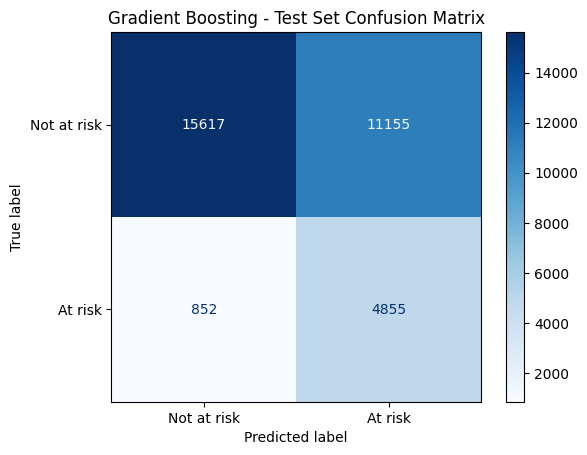

In [ ]:
test_raw_probs = best_model.predict_proba(X_test_scaled)[:, 1]
test_calibrated = calibrate(test_raw_probs)
test_preds = (test_calibrated >= threshold).astype(int)

auc = roc_auc_score(y_test, test_calibrated)
precision = precision_score(y_test, test_preds)
recall = recall_score(y_test, test_preds)
accuracy = accuracy_score(y_test, test_preds)

print(f"=== {best_name} at threshold {threshold:.3f} ===")
print(f"AUC:       {auc:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"Accuracy:  {accuracy:.3f}")

cm = confusion_matrix(y_test, test_preds, labels=[0, 1])
print("\nConfusion matrix:")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not at risk", "At risk"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"{best_name} - Test Set Confusion Matrix")
plt.show()

## Feature importance

Use SHAP to examine which features contribute most to the predictions. This analysis is separate from the app's recommendation rules.


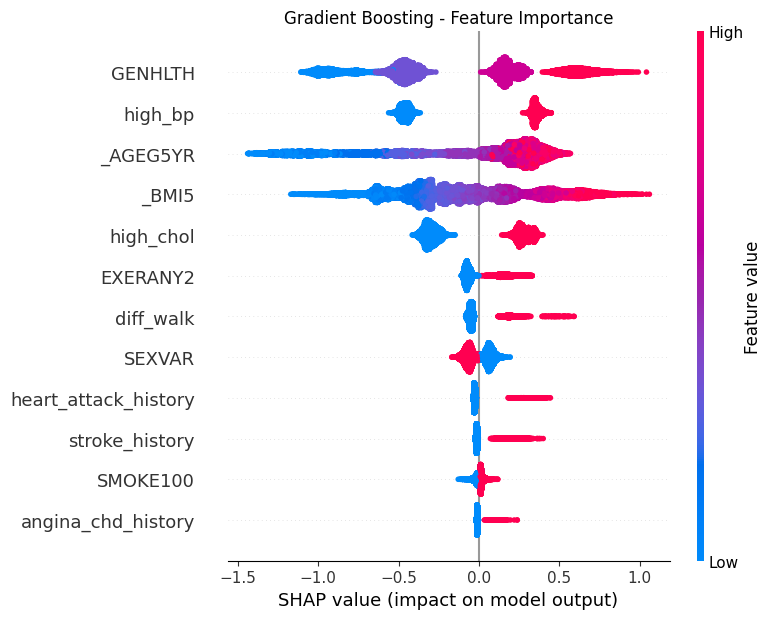

In [ ]:
try:
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_test_scaled)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif np.array(shap_values).ndim == 3:
        shap_values = shap_values[:, :, 1]
except Exception as e:
    print(f"TreeExplainer didn't work ({e}), using the slower general explainer instead")
    background = shap.sample(X_test_scaled, 100, random_state=42)
    sample = shap.sample(X_test_scaled, 300, random_state=42)
    explainer = shap.Explainer(best_model.predict_proba, background)
    shap_values = explainer(sample).values[:, :, 1]
    X_test_scaled = sample

shap.summary_plot(shap_values, X_test_scaled, feature_names=FEATURES, show=False)
plt.title(f"{best_name} - Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)
ranking = sorted(zip(FEATURES, mean_abs_shap.tolist()), key=lambda x: -x[1])

print("export const FEATURE_IMPORTANCE = [")
for feature, importance in ranking:
    print(f'  {{ feature: "{feature}", importance: {importance:.4f} }},')
print("];")

export const FEATURE_IMPORTANCE = [
  { feature: "GENHLTH", importance: 0.4608 },
  { feature: "high_bp", importance: 0.4122 },
  { feature: "_AGEG5YR", importance: 0.4013 },
  { feature: "_BMI5", importance: 0.3504 },
  { feature: "high_chol", importance: 0.2922 },
  { feature: "EXERANY2", importance: 0.0933 },
  { feature: "diff_walk", importance: 0.0749 },
  { feature: "SEXVAR", importance: 0.0672 },
  { feature: "heart_attack_history", importance: 0.0417 },
  { feature: "stroke_history", importance: 0.0215 },
  { feature: "SMOKE100", importance: 0.0203 },
  { feature: "angina_chd_history", importance: 0.0169 },
];


## Save the model

Save the fitted classifier and scaler as joblib files so they can be reused without retraining.


In [ ]:
from google.colab import files

joblib.dump(best_model, "diabetes_risk_model.joblib")
joblib.dump(scaler, "diabetes_risk_scaler.joblib")

with open("model_info.txt", "w") as f:
    f.write(f"Model: {best_name}\n")
    f.write(f"Threshold: {threshold:.3f}\n")
    f.write(f"Validation AUC: {val_scores[best_name]:.3f}\n")
    f.write(f"Features: {FEATURES}\n")

files.download("diabetes_risk_model.joblib")
files.download("diabetes_risk_scaler.joblib")
files.download("model_info.txt")
print("Saved and downloaded.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved and downloaded.


## Export to ONNX

Bundle the scaler and classifier into one pipeline for the phone to run. Set zipmap=False so the probabilities are returned as an array.


In [ ]:
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType

export_pipeline = Pipeline([
    ("scaler", scaler),
    ("model", best_model),
])

initial_type = [("float_input", FloatTensorType([None, len(FEATURES)]))]
options = {id(best_model): {"zipmap": False}}
onnx_model = convert_sklearn(export_pipeline, initial_types=initial_type, target_opset=15, options=options)

with open("diabetes_risk_model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

print(f"Saved diabetes_risk_model.onnx ({len(onnx_model.SerializeToString()):,} bytes)")

Saved diabetes_risk_model.onnx (55,893 bytes)


## Check the export

Compare scikit-learn and ONNX predictions on five test rows.


In [ ]:
import onnxruntime as rt

session = rt.InferenceSession("diabetes_risk_model.onnx", providers=["CPUExecutionProvider"])
input_name = session.get_inputs()[0].name

check_rows_df = X_test.iloc[:5]
check_rows_np = check_rows_df.to_numpy().astype(np.float32)

sklearn_probs = export_pipeline.predict_proba(check_rows_df)[:, 1]

# Extract the positive-class probability from the ONNX array.
onnx_labels, onnx_probs_array = session.run(None, {input_name: check_rows_np})
onnx_probs = onnx_probs_array[:, 1]

print("scikit-learn:", np.round(sklearn_probs, 4))
print("ONNX:        ", np.round(onnx_probs, 4))
print("Match:", np.allclose(sklearn_probs, onnx_probs, atol=1e-4))

files.download("diabetes_risk_model.onnx")

scikit-learn: [0.5444 0.221  0.2787 0.7142 0.7785]
ONNX:         [0.5444 0.221  0.2787 0.7142 0.7785]
Match: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Use in the app

Place diabetes_risk_model.onnx in assets/model/. Keep the calibration values and cutoff in src/constants.js consistent with this run.
